## **#Importing necessary libraries for data manipulation**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib . pyplot as plt
import scipy.stats as stats
import seaborn as sns

### **#Load tables into the notebook**

In [ ]:
orders = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/orders.csv")
products = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/products.csv")
aisles= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/aisles.csv")
departments= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/departments.csv")
orderprodprior= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__prior.csv")
orderprodtrain= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__train.csv")

# **C1**

---



# **#Verifying  test statistic**

In [ ]:
sample_mean = 16.1417
pop_sd = 6.915575
n = 100
hyp_mean = 7

# Calculate Z-stat and p-value
z_stat = (sample_mean - hyp_mean) / (pop_sd / np.sqrt(n))
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print(f"Z-statistic: {z_stat:.2f}")
print(f"p-value: {p_value:.4e}")

Z-statistic: 13.22
p-value: 0.0000e+00


# **C2**

---



# **#Computing group means**

In [ ]:
# 1. Compute order sizes
order_size = orderprodprior.groupby('order_id').size().reset_index(name='order_size')

# 2. Merge 'order_size' into 'orders' DataFrame
# check if 'order_size' is already there to prevent KeyError on re-runs
if 'order_size' not in orders.columns:
    orders = orders.merge(order_size, on='order_id')

# 3. Create the Weekend Indicator
# Sunday (0) and Saturday (6) are marked as 1, others as 0
orders['weekend'] = orders['order_dow'].apply(lambda x: 1 if x in [0, 6] else 0)

# 4. Compute Group Means (Point Estimates)
group_means = orders.groupby('weekend')['order_size'].mean()

# Assign to specific variables for formal hypothesis testing
x_bar_w = group_means[1]  # Mean Weekend Order Size (weekend is 1)
x_bar_d = group_means[0]  # Mean Weekday Order Size (weekday is 0)

print(f"Point Estimate Weekend (x_bar_w): {x_bar_w:.4f} items")
print(f"Point Estimate Weekday (x_bar_d): {x_bar_d:.4f} items")

Point Estimate Weekend (x_bar_w): 10.9664 items
Point Estimate Weekday (x_bar_d): 9.7060 items


* Business Logic: Baskets are 13% larger on weekends, requiring increased staffing and logistics optimization

**#Computing Test Statistic**

In [ ]:
# Extract the specific groups for the test
# Using the orders DataFrame and weekend indicator
weekend_basket_sizes = orders[orders['weekend'] == 1]['order_size']
weekday_basket_sizes = orders[orders['weekend'] == 0]['order_size']

# Compute the Test Statistic
# Use Welch’s t-test (equal_var=False)
t_stat, p_val = stats.ttest_ind(weekend_basket_sizes, weekday_basket_sizes, equal_var=False)

print(f"Calculated t-statistic: {t_stat:.4f}")
print(f"Calculated p-value: {p_val:.4e}")

# 4. Decision Rule Check (Alpha = 0.05)
if p_val < 0.05:
    print("Conclusion: Reject the Null Hypothesis (H0).")
else:
    print("Conclusion: Fail to Reject the Null Hypothesis (H0).")

Calculated t-statistic: 136.2849
Calculated p-value: 0.0000e+00
Conclusion: Reject the Null Hypothesis (H0).


* Decision Rule Used: If calculated p-value < 0.05, reject the null hypothesis.
* Statistical Conclusion: There is sufficient statistical evidence to conclude that the true population mean order size for weekends differs significantly from that of weekdays.

# **C3**

---



**#Correlation & Rgression scatter Plot**

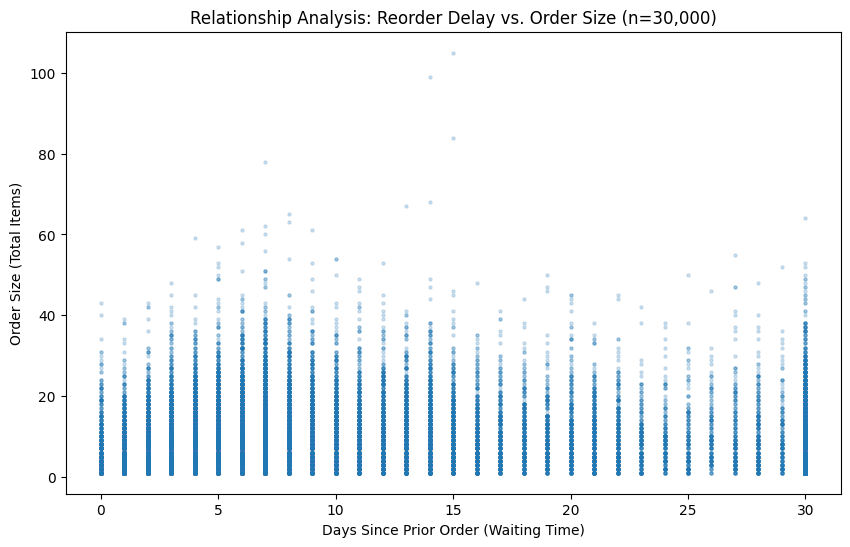

In [ ]:
# group the items by order_id and count them to define 'order_size'
order_items = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__prior.csv")
order_size_df = order_items.groupby('order_id').size().reset_index(name='order_size')

# Merge 'order_size' into main 'orders' DataFrame
if 'order_size' not in orders.columns:
    orders = orders.merge(order_size_df, on='order_id')

# Handle Missing Values
# First-time orders have NaN in 'days_since_prior_order' and must be removed for correlation
clean_data = orders[['days_since_prior_order', 'order_size']].dropna()

# Random Sampling for Visual Clarity (n=30,000)
# This prevents 'Overplotting Density' caused by the massive dataset size
tmp_sampled = clean_data.sample(n=30000, random_state=42)

# Construct the Scatter Plot
plt.figure(figsize=(10, 6))

# Use small markers (s=5) and low alpha (0.2) to reveal density patterns
plt.scatter(tmp_sampled['days_since_prior_order'],
            tmp_sampled['order_size'],
            alpha=0.2,
            s=5,
            color='tab:blue')

# Formatting and Labels

plt.xlabel("Days Since Prior Order (Waiting Time)")
plt.ylabel("Order Size (Total Items)")
plt.title("Relationship Analysis: Reorder Delay vs. Order Size (n=30,000)")
plt.show()

* stockpiling

**#Extracting correlation coeffecient values**

In [ ]:
# group the items by order_id and count them to define 'order_size'
order_items = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__prior.csv")
order_size_df = order_items.groupby('order_id').size().reset_index(name='order_size')

# Merge 'order_size' into main 'orders' DataFrame
if 'order_size' not in orders.columns:
    orders = orders.merge(order_size_df, on='order_id')

# Handle Missing Values
# First-time orders have NaN in 'days_since_prior_order' and must be removed for correlation
clean_data = orders[['days_since_prior_order', 'order_size']].dropna()

# clean_data was defined in previous steps as orders[['days_since_prior_order', 'order_size']].dropna()
x = clean_data['days_since_prior_order']
y = clean_data['order_size']

# 2. Calculate the six necessary summary components
n = len(clean_data)
sum_x = x.sum()
sum_y = y.sum()
sum_x2 = (x**2).sum()
sum_y2 = (y**2).sum()
sum_xy = (x * y).sum()

# 3. Print the values
print(f"n: {n}")
print(f"Sum of X (sum_x): {sum_x}")
print(f"Sum of Y (sum_y): {sum_y}")
print(f"Sum of X^2 (sum_x2): {sum_x2}")
print(f"Sum of Y^2 (sum_y2): {sum_y2}")
print(f"Sum of XY (sum_xy): {sum_xy}")

n: 3008665
Sum of X (sum_x): 32214505.0
Sum of Y (sum_y): 30356421
Sum of X^2 (sum_x2): 586155195.0
Sum of Y^2 (sum_y2): 476847725
Sum of XY (sum_xy): 337079953.0


# **#Computing correlation coefficient**

In [ ]:
# Values from Above
n = 3008665
sum_x = 32214505.0
sum_y = 30356421
sum_x2 = 586155195.0
sum_y2 = 476847725
sum_xy = 337079953.0

# Formula: r = (n*sum_xy - sum_x*sum_y) / sqrt([n*sum_x2 - sum_x^2] * [n*sum_y2 - sum_y^2])
numerator = (n * sum_xy) - (sum_x * sum_y)
denominator = np.sqrt((n * sum_x2 - sum_x**2) * (n * sum_y2 - sum_y**2))
r = numerator / denominator

print(f"Correlation Coefficient (r): {r:.4f}")

Correlation Coefficient (r): 0.0594


* This indicates a very weak positive linear relationship

# **#Test significance of correlation**

In [ ]:
# r = 0.0594, n = 3008665
r = 0.0594
n = 3008665

# Compute t-statistic: t = r * sqrt((n-2)/(1-r^2))
t_stat = r * np.sqrt((n - 2) / (1 - r**2))

# Compute p-value (two-tailed)
p_val = stats.t.sf(np.abs(t_stat), n - 2) * 2

print(f"t-statistic: {t_stat:.4f}")
print(f"p-value: {p_val:.4f}")

t-statistic: 103.2145
p-value: 0.0000


* Decision: With n>3million, the critical value for a two-tailed test is 1.96. Since 103.25> 1.96, we reject H0

# **#Estimate regression model**

In [ ]:
# Formula for slope (b1) and intercept (b0)
# b1 = (n*sum_xy - sum_x*sum_y) / (n*sum_x2 - sum_x^2)
b1 = 36243616456140 / 725770733333650

# Mean of X and Y
mean_x = 32214505.0 / 3008665
mean_y = 30356421 / 3008665

b0 = mean_y - (b1 * mean_x)

print(f"Regression Equation: OrderSize = {b0:.4f} + {b1:.4f} * DaysSincePriorOrder")

Regression Equation: OrderSize = 9.5550 + 0.0499 * DaysSincePriorOrder


* Intercept(b0=9.555):  A customer returning immediately (0 days delay) is
predicted to buy approximately 9.56 items.

* Slope (b1=0.050): This is the marginal rate of change. For every 1 additional day a customer waits to reorder, their basket size is predicted to increase by only 0.05 items.


# **#Interpret R2**

In [ ]:
r_sq = r**2
print(f"R-squared (R2): {r_sq:.4f}")

R-squared (R2): 0.0035


Only 0.35% of the variation in order size is explained by the number of days since the prior order.